# **LABSHEET - 6**
**Mishti Verma(CU24250174)**
---

**1. Build a threshold-based segmentation tool with adjustable global and adaptive thresholds.**

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
import ipywidgets as widgets
from IPython.display import display

# Upload image
uploaded = files.upload()
filename = next(iter(uploaded))

image = cv2.imread(filename)

if image is None:
    print("Error: Image could not be loaded.")
else:

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Sliders
    global_threshold = widgets.IntSlider(
        value=127,
        min=0,
        max=255,
        step=1,
        description="Global:"
    )

    block_size = widgets.IntSlider(
        value=11,
        min=3,
        max=51,
        step=2,
        description="Block:"
    )

    adaptive_c = widgets.IntSlider(
        value=2,
        min=-20,
        max=20,
        step=1,
        description="C:"
    )

    method = widgets.Dropdown(
        options=[
            "Global Threshold",
            "Adaptive Mean",
            "Adaptive Gaussian"
        ],
        value="Global Threshold",
        description="Method:"
    )

    output = widgets.Output()

    def update(change=None):

        with output:
            output.clear_output(wait=True)

            if method.value == "Global Threshold":

                _, segmented = cv2.threshold(
                    gray,
                    global_threshold.value,
                    255,
                    cv2.THRESH_BINARY
                )

            elif method.value == "Adaptive Mean":

                segmented = cv2.adaptiveThreshold(
                    gray,
                    255,
                    cv2.ADAPTIVE_THRESH_MEAN_C,
                    cv2.THRESH_BINARY,
                    block_size.value,
                    adaptive_c.value
                )

            else:

                segmented = cv2.adaptiveThreshold(
                    gray,
                    255,
                    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                    cv2.THRESH_BINARY,
                    block_size.value,
                    adaptive_c.value
                )

            plt.figure(figsize=(12, 4))

            plt.subplot(1, 3, 1)
            plt.imshow(
                cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            )
            plt.title("Original Image")
            plt.axis("off")

            plt.subplot(1, 3, 2)
            plt.imshow(gray, cmap="gray")
            plt.title("Grayscale Image")
            plt.axis("off")

            plt.subplot(1, 3, 3)
            plt.imshow(segmented, cmap="gray")
            plt.title(method.value)
            plt.axis("off")

            plt.tight_layout()
            plt.show()

    global_threshold.observe(update, names="value")
    block_size.observe(update, names="value")
    adaptive_c.observe(update, names="value")
    method.observe(update, names="value")

    display(
        method,
        global_threshold,
        block_size,
        adaptive_c,
        output
    )

    update()

Saving pic(cat).jpg to pic(cat).jpg


Dropdown(description='Method:', options=('Global Threshold', 'Adaptive Mean', 'Adaptive Gaussian'), value='Glo…

IntSlider(value=127, description='Global:', max=255)

IntSlider(value=11, description='Block:', max=51, min=3, step=2)

IntSlider(value=2, description='C:', max=20, min=-20)

Output()

**Mishti Verma(CU24250174)**

**2. Develop a region-growing segmentation tool that segments an image starting from user-selected seed points.**

In [ ]:
import ipywidgets as widgets
from IPython.display import display

# Upload image
uploaded = files.upload()
filename = next(iter(uploaded))

image = cv2.imread(filename)

if image is None:
    print("Error: Image could not be loaded.")
else:

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Resize for easier processing
    max_size = 500

    h, w = gray.shape

    if max(h, w) > max_size:
        scale = max_size / max(h, w)
        gray = cv2.resize(
            gray,
            (int(w * scale), int(h * scale))
        )

    h, w = gray.shape

    # Region growing function
    def region_growing(image, seeds, tolerance):

        height, width = image.shape
        segmented = np.zeros((height, width), dtype=np.uint8)

        visited = np.zeros(
            (height, width),
            dtype=bool
        )

        queue = []

        for x, y in seeds:

            if 0 <= x < width and 0 <= y < height:

                queue.append((x, y))
                visited[y, x] = True
                segmented[y, x] = 255

        while queue:

            x, y = queue.pop(0)

            current_value = int(image[y, x])

            neighbors = [
                (x - 1, y),
                (x + 1, y),
                (x, y - 1),
                (x, y + 1)
            ]

            for nx, ny in neighbors:

                if (
                    0 <= nx < width
                    and 0 <= ny < height
                    and not visited[ny, nx]
                ):

                    neighbor_value = int(
                        image[ny, nx]
                    )

                    if abs(
                        neighbor_value - current_value
                    ) <= tolerance:

                        visited[ny, nx] = True
                        segmented[ny, nx] = 255
                        queue.append((nx, ny))

        return segmented


    # Seed point controls
    x1 = widgets.IntSlider(
        value=w // 2,
        min=0,
        max=w - 1,
        description="Seed 1 X:"
    )

    y1 = widgets.IntSlider(
        value=h // 2,
        min=0,
        max=h - 1,
        description="Seed 1 Y:"
    )

    x2 = widgets.IntSlider(
        value=w // 3,
        min=0,
        max=w - 1,
        description="Seed 2 X:"
    )

    y2 = widgets.IntSlider(
        value=h // 3,
        min=0,
        max=h - 1,
        description="Seed 2 Y:"
    )

    tolerance = widgets.IntSlider(
        value=10,
        min=1,
        max=50,
        step=1,
        description="Tolerance:"
    )

    output = widgets.Output()

    def update(change=None):

        seeds = [
            (x1.value, y1.value),
            (x2.value, y2.value)
        ]

        segmented = region_growing(
            gray,
            seeds,
            tolerance.value
        )

        with output:

            output.clear_output(wait=True)

            display_image = cv2.cvtColor(
                image,
                cv2.COLOR_BGR2RGB
            )

            plt.figure(figsize=(8, 3))

            plt.subplot(1, 3, 1)
            plt.imshow(gray, cmap="gray")
            plt.scatter(
                [x1.value, x2.value],
                [y1.value, y2.value],
                c="red",
                s=40
            )
            plt.title("Selected Seed Points")
            plt.axis("off")

            plt.subplot(1, 3, 2)
            plt.imshow(display_image)
            plt.scatter(
                [x1.value, x2.value],
                [y1.value, y2.value],
                c="red",
                s=40
            )
            plt.title("Original Image")
            plt.axis("off")

            plt.subplot(1, 3, 3)
            plt.imshow(segmented, cmap="gray")
            plt.title(
                "Region Growing Segmentation"
            )
            plt.axis("off")

            plt.tight_layout()
            plt.show()


    x1.observe(update, names="value")
    y1.observe(update, names="value")
    x2.observe(update, names="value")
    y2.observe(update, names="value")
    tolerance.observe(update, names="value")

    display(
        x1,
        y1,
        x2,
        y2,
        tolerance,
        output
    )

    update()

Saving pic(cat).jpg to pic(cat) (3).jpg


IntSlider(value=197, description='Seed 1 X:', max=394)

IntSlider(value=249, description='Seed 1 Y:', max=498)

IntSlider(value=131, description='Seed 2 X:', max=394)

IntSlider(value=166, description='Seed 2 Y:', max=498)

IntSlider(value=10, description='Tolerance:', max=50, min=1)

Output()

**Mishti Verma(CU24250174)**

**3. Create a split-and-merge segmentation demo on a textured or satellite image.**

Saving satellite img.jpg to satellite img (1).jpg


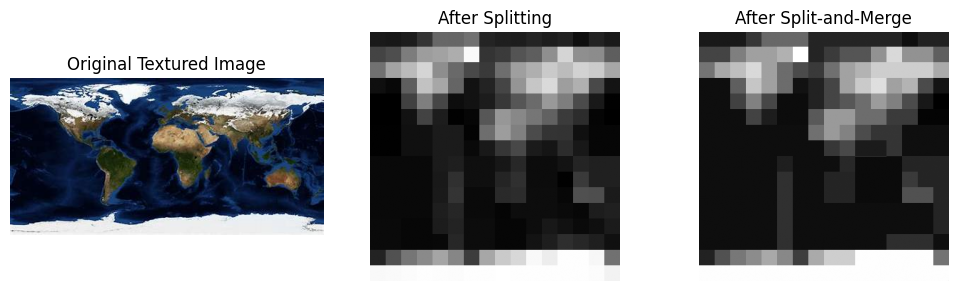

Number of regions after splitting: 196


In [ ]:
uploaded = files.upload()
filename = next(iter(uploaded))

image = cv2.imread(filename)

if image is None:
    print("Error: Image could not be loaded.")
else:

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Resize image for faster processing
    gray = cv2.resize(gray, (256, 256))

    # Parameters
    variance_threshold = 400
    min_size = 16

    regions = []

    def split_region(x, y, w, h):

        region = gray[y:y+h, x:x+w]

        mean = np.mean(region)
        variance = np.var(region)

        if (
            variance <= variance_threshold
            or w <= min_size
            or h <= min_size
        ):
            regions.append(
                (x, y, w, h, mean)
            )
            return

        half_w = w // 2
        half_h = h // 2

        split_region(x, y, half_w, half_h)
        split_region(
            x + half_w,
            y,
            w - half_w,
            half_h
        )
        split_region(
            x,
            y + half_h,
            half_w,
            h - half_h
        )
        split_region(
            x + half_w,
            y + half_h,
            w - half_w,
            h - half_h
        )

    # Start splitting
    split_region(
        0,
        0,
        gray.shape[1],
        gray.shape[0]
    )

    # Create segmented image
    segmented = np.zeros_like(gray)

    for x, y, w, h, mean in regions:
        segmented[y:y+h, x:x+w] = mean

    # Merge neighboring regions
    merged = segmented.copy()

    for y in range(0, gray.shape[0] - 1):
        for x in range(0, gray.shape[1] - 1):

            current = int(merged[y, x])
            right = int(merged[y, x + 1])
            below = int(merged[y + 1, x])

            if abs(current - right) < 15:
                merged[y, x + 1] = current

            if abs(current - below) < 15:
                merged[y + 1, x] = current

    # Display results
    plt.figure(figsize=(10, 3))

    plt.subplot(1, 3, 1)
    plt.imshow(
        cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    )
    plt.title("Original Textured Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(segmented, cmap="gray")
    plt.title("After Splitting")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(merged, cmap="gray")
    plt.title("After Split-and-Merge")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Number of regions after splitting:", len(regions))

**4. Build a watershed segmentation tool to separate touching or overlapping objects(eg: coins or cells).**

In [ ]:
# Upload image
uploaded = files.upload()
filename = next(iter(uploaded))

image = cv2.imread(filename)

if image is None:
    print("Error: Image could not be loaded.")
else:

    # Convert to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Blur image
    blur = cv2.GaussianBlur(gray, (5, 5), 0)

    # Binary threshold
    _, binary = cv2.threshold(
        blur,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    # Remove noise
    kernel = np.ones((3, 3), np.uint8)

    opening = cv2.morphologyEx(
        binary,
        cv2.MORPH_OPEN,
        kernel,
        iterations=2
    )

    # Sure background
    sure_bg = cv2.dilate(
        opening,
        kernel,
        iterations=3
    )

    # Distance transform
    distance = cv2.distanceTransform(
        opening,
        cv2.DIST_L2,
        5
    )

    # Sure foreground
    _, sure_fg = cv2.threshold(
        distance,
        0.4 * distance.max(),
        255,
        0
    )

    sure_fg = np.uint8(sure_fg)

    # Unknown region
    unknown = cv2.subtract(
        sure_bg,
        sure_fg
    )

    # Marker labeling
    _, markers = cv2.connectedComponents(
        sure_fg
    )

    # Add one to background
    markers = markers + 1

    # Mark unknown region as 0
    markers[unknown == 255] = 0

    # Apply watershed
    image_copy = image.copy()

    markers = cv2.watershed(
        image_copy,
        markers
    )

    # Draw watershed boundaries
    image_copy[markers == -1] = [0, 0, 255]

    # Display results
    plt.figure(figsize=(15, 8))

    plt.subplot(2, 3, 1)
    plt.imshow(
        cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    )
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(2, 3, 2)
    plt.imshow(gray, cmap="gray")
    plt.title("Grayscale")
    plt.axis("off")

    plt.subplot(2, 3, 3)
    plt.imshow(binary, cmap="gray")
    plt.title("Binary Image")
    plt.axis("off")

    plt.subplot(2, 3, 4)
    plt.imshow(distance, cmap="gray")
    plt.title("Distance Transform")
    plt.axis("off")

    plt.subplot(2, 3, 5)
    plt.imshow(sure_fg, cmap="gray")
    plt.title("Sure Foreground")
    plt.axis("off")

    plt.subplot(2, 3, 6)
    plt.imshow(
        cv2.cvtColor(image_copy, cv2.COLOR_BGR2RGB)
    )
    plt.title("Watershed Segmentation")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    # Count detected objects
    object_count = len(np.unique(markers)) - 2

    print("Approximate number of separated objects:", object_count)

**5. Develop a K-means or mean-shift color segmentation tool that clusters image regions by color similarity.**

In [ ]:
# Upload image
uploaded = files.upload()
filename = next(iter(uploaded))

image = cv2.imread(filename)

if image is None:
    print("Error: Image could not be loaded.")
else:

    # Convert BGR to RGB
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Resize for faster processing
    image_rgb = cv2.resize(image_rgb, (400, 400))

    # Convert image into a list of pixels
    pixels = image_rgb.reshape((-1, 3))
    pixels = np.float32(pixels)

    # K-means parameters
    criteria = (
        cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
        100,
        0.2
    )

    # Slider for number of clusters
    k_slider = widgets.IntSlider(
        value=3,
        min=2,
        max=10,
        step=1,
        description="Clusters:",
        continuous_update=False
    )

    def segment_image(k):

        # Apply K-means clustering
        _, labels, centers = cv2.kmeans(
            pixels,
            k,
            None,
            criteria,
            10,
            cv2.KMEANS_RANDOM_CENTERS
        )

        # Convert cluster centers to uint8
        centers = np.uint8(centers)

        # Replace every pixel with its cluster center
        segmented_pixels = centers[labels.flatten()]

        # Reshape back to image
        segmented = segmented_pixels.reshape(image_rgb.shape)

        # Display results
        plt.figure(figsize=(8, 3))

        plt.subplot(1, 2, 1)
        plt.imshow(image_rgb)
        plt.title("Original Image")
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(segmented)
        plt.title(f"K-means Segmentation (K = {k})")
        plt.axis("off")

        plt.tight_layout()
        plt.show()

        print("Number of color clusters:", k)
        print("Cluster center colors (RGB):")
        print(centers)

    # Interactive segmentation
    widgets.interact(segment_image, k=k_slider)

Saving pic(nature).jpg to pic(nature).jpg


interactive(children=(IntSlider(value=3, continuous_update=False, description='Clusters:', max=10, min=2), Out…

**6. Create an interactive foreground-extraction tool using a graph-based method such as GrabCut.**

In [ ]:
# Upload image
uploaded = files.upload()
filename = next(iter(uploaded))

image = cv2.imread(filename)

if image is None:
    print("Error: Image could not be loaded.")
else:

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Resize image for faster processing
    max_size = 600
    scale = min(max_size / image.shape[1], max_size / image.shape[0], 1)

    if scale < 1:
        image = cv2.resize(
            image,
            (int(image.shape[1] * scale), int(image.shape[0] * scale))
        )

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    h, w = image.shape[:2]

    # Interactive rectangle controls
    x_slider = widgets.IntSlider(
        value=int(w * 0.15),
        min=0,
        max=w - 10,
        step=1,
        description="X:"
    )

    y_slider = widgets.IntSlider(
        value=int(h * 0.15),
        min=0,
        max=h - 10,
        step=1,
        description="Y:"
    )

    width_slider = widgets.IntSlider(
        value=int(w * 0.7),
        min=20,
        max=w,
        step=1,
        description="Width:"
    )

    height_slider = widgets.IntSlider(
        value=int(h * 0.7),
        min=20,
        max=h,
        step=1,
        description="Height:"
    )

    iterations_slider = widgets.IntSlider(
        value=5,
        min=1,
        max=10,
        step=1,
        description="Iterations:"
    )

    def grabcut(x, y, width, height, iterations):

        # Keep rectangle inside image
        width = min(width, w - x)
        height = min(height, h - y)

        if width <= 1 or height <= 1:
            print("Invalid rectangle.")
            return

        # Initial mask
        mask = np.zeros((h, w), np.uint8)

        # Background outside rectangle
        mask[:] = cv2.GC_BGD

        # Rectangle is probable foreground
        mask[y:y+height, x:x+width] = cv2.GC_PR_FGD

        # GrabCut models
        bgd_model = np.zeros((1, 65), np.float64)
        fgd_model = np.zeros((1, 65), np.float64)

        # Apply GrabCut
        cv2.grabCut(
            image,
            mask,
            (x, y, width, height),
            bgd_model,
            fgd_model,
            iterations,
            cv2.GC_INIT_WITH_RECT
        )

        # Create foreground mask
        foreground_mask = np.where(
            (mask == cv2.GC_FGD) | (mask == cv2.GC_PR_FGD),
            255,
            0
        ).astype("uint8")

        # Extract foreground
        foreground = cv2.bitwise_and(
            image_rgb,
            image_rgb,
            mask=foreground_mask
        )

        # Draw rectangle on original image
        preview = image_rgb.copy()

        cv2.rectangle(
            preview,
            (x, y),
            (x + width, y + height),
            (255, 0, 0),
            2
        )

        # Display results
        plt.figure(figsize=(8, 3))

        plt.subplot(1, 3, 1)
        plt.imshow(preview)
        plt.title("Input + Foreground Rectangle")
        plt.axis("off")

        plt.subplot(1, 3, 2)
        plt.imshow(foreground_mask, cmap="gray")
        plt.title("GrabCut Mask")
        plt.axis("off")

        plt.subplot(1, 3, 3)
        plt.imshow(foreground)
        plt.title("Extracted Foreground")
        plt.axis("off")

        plt.tight_layout()
        plt.show()

    # Interactive tool
    widgets.interact(
        grabcut,
        x=x_slider,
        y=y_slider,
        width=width_slider,
        height=height_slider,
        iterations=iterations_slider
    )

Saving pic(nature).jpg to pic(nature) (1).jpg


interactive(children=(IntSlider(value=90, description='X:', max=590), IntSlider(value=45, description='Y:', ma…

**7. Build a normalized-cut based segmentation demo that partitions an image into meaningful regions.**

Saving pic(nature).jpg to pic(nature) (3).jpg


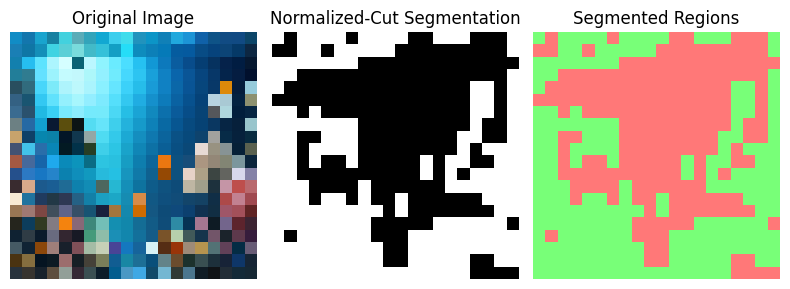

Normalized-Cut segmentation completed successfully.
Image size used: (20, 20)
Number of graph nodes: 400
Smallest eigenvalues: [1.66717582e-16 1.18507483e-06 4.23543193e-06 7.11502845e-04
 1.36258857e-03]


In [ ]:
# Upload image
uploaded = files.upload()
filename = next(iter(uploaded))

image = cv2.imread(filename)

if image is None:
    print("Error: Image could not be loaded.")
else:

    # Convert BGR to RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Small image for Normalized Cut
    image = cv2.resize(image, (20, 20))

    h, w, _ = image.shape
    n = h * w

    pixels = image.astype(np.float64)

    # Step 1: Create similarity matrix

    W = np.zeros((n, n), dtype=np.float64)

    sigma_color = 40.0

    for y in range(h):
        for x in range(w):

            current = y * w + x

            neighbours = [
                (y, x + 1),
                (y + 1, x)
            ]

            for ny, nx in neighbours:

                if 0 <= ny < h and 0 <= nx < w:

                    neighbour = ny * w + nx

                    color_diff = np.linalg.norm(
                        pixels[y, x] - pixels[ny, nx]
                    )

                    weight = np.exp(
                        -(color_diff ** 2) /
                        (2 * sigma_color ** 2)
                    )

                    W[current, neighbour] = weight
                    W[neighbour, current] = weight

    # Step 2: Degree matrix

    degree = np.sum(W, axis=1)

    # Avoid division by zero
    degree[degree == 0] = 1e-10

    D_inv_sqrt = np.diag(
        1.0 / np.sqrt(degree)
    )

    # Step 3: Normalized Laplacian
    # L = I - D^(-1/2) W D^(-1/2)

    I = np.eye(n)

    L = I - D_inv_sqrt @ W @ D_inv_sqrt

    # Make matrix symmetric to avoid numerical issues
    L = (L + L.T) / 2

    # Step 4: Calculate eigenvalues/eigenvectors

    eigenvalues, eigenvectors = np.linalg.eigh(L)

    # Second smallest eigenvector
    second_vector = eigenvectors[:, 1]

    # Step 5: Partition image

    threshold = np.median(second_vector)

    segmentation = (
        second_vector > threshold
    ).astype(np.uint8)

    segmentation = segmentation.reshape(h, w)

    # Step 6: Create colored segmentation

    segmented = np.zeros_like(image)

    segmented[segmentation == 0] = [255, 120, 120]
    segmented[segmentation == 1] = [120, 255, 120]

    # Step 7: Display results

    plt.figure(figsize=(8, 3))

    plt.subplot(1, 3, 1)
    plt.imshow(image)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(segmentation, cmap="gray")
    plt.title("Normalized-Cut Segmentation")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(segmented)
    plt.title("Segmented Regions")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Normalized-Cut segmentation completed successfully.")
    print("Image size used:", image.shape[:2])
    print("Number of graph nodes:", n)
    print("Smallest eigenvalues:", eigenvalues[:5])

**8. Develop a medical image segmentation tool(eg: isolating a tumour or organ outline from a grayscale scan).**

Saving medical img.jpg to medical img.jpg


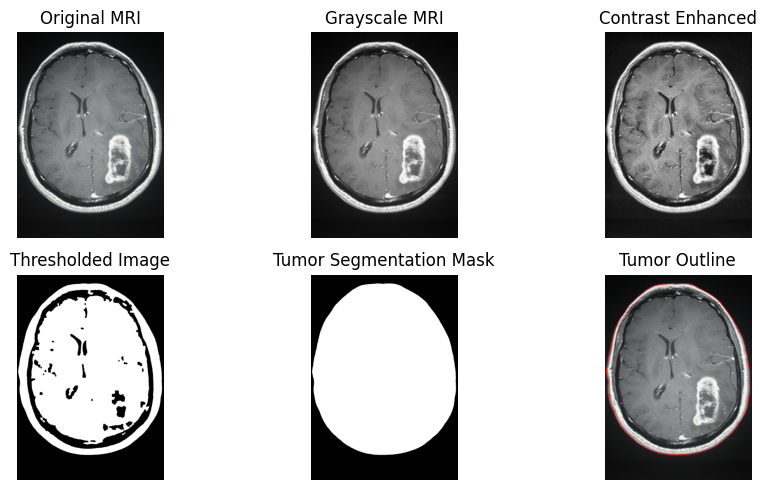

Number of segmented regions: 1
Medical image segmentation completed.


In [ ]:
# Upload MRI image
uploaded = files.upload()
filename = next(iter(uploaded))

# Read image
image = cv2.imread(filename)

if image is None:
    print("Error: Image could not be loaded.")
else:

    # Convert to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Improve contrast
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)

    # Smooth image
    blurred = cv2.GaussianBlur(enhanced, (5, 5), 0)

    # Threshold bright regions
    _, binary = cv2.threshold(
        blurred, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Remove small noise
    kernel = np.ones((5, 5), np.uint8)

    binary = cv2.morphologyEx(
        binary,
        cv2.MORPH_OPEN,
        kernel,
        iterations=2
    )

    binary = cv2.morphologyEx(
        binary,
        cv2.MORPH_CLOSE,
        kernel,
        iterations=2
    )

    # Find contours
    contours, _ = cv2.findContours(
        binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    # Create tumor mask
    tumor_mask = np.zeros_like(gray)

    # Keep sufficiently large regions
    for contour in contours:
        area = cv2.contourArea(contour)

        if area > 500:
            cv2.drawContours(
                tumor_mask,
                [contour],
                -1,
                255,
                -1
            )

    # Find final tumor contours
    tumor_contours, _ = cv2.findContours(
        tumor_mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    # Draw tumor outline
    result = image.copy()

    cv2.drawContours(
        result,
        tumor_contours,
        -1,
        (0, 0, 255),
        3
    )

    # Extract segmented tumor
    tumor = cv2.bitwise_and(
        image,
        image,
        mask=tumor_mask
    )

    # Display results
    plt.figure(figsize=(10, 5))

    plt.subplot(2, 3, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Original MRI")
    plt.axis("off")

    plt.subplot(2, 3, 2)
    plt.imshow(gray, cmap="gray")
    plt.title("Grayscale MRI")
    plt.axis("off")

    plt.subplot(2, 3, 3)
    plt.imshow(enhanced, cmap="gray")
    plt.title("Contrast Enhanced")
    plt.axis("off")

    plt.subplot(2, 3, 4)
    plt.imshow(binary, cmap="gray")
    plt.title("Thresholded Image")
    plt.axis("off")

    plt.subplot(2, 3, 5)
    plt.imshow(tumor_mask, cmap="gray")
    plt.title("Tumor Segmentation Mask")
    plt.axis("off")

    plt.subplot(2, 3, 6)
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title("Tumor Outline")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Number of segmented regions:", len(tumor_contours))
    print("Medical image segmentation completed.")

**9. Create a license-plate or text-region segmentation tool that isolates text areas from vehicle or document image.**

Saving car img.jpg to car img.jpg


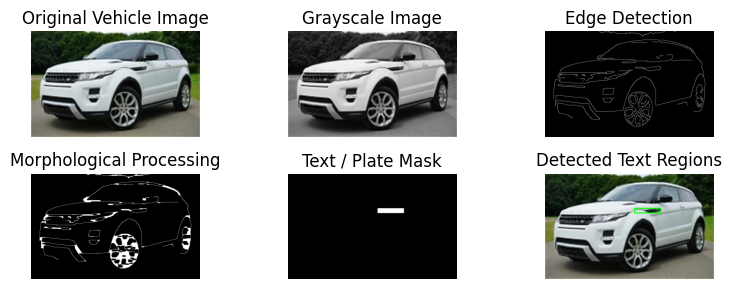

Number of detected text/plate regions: 1


In [ ]:
# Upload vehicle image
uploaded = files.upload()
filename = next(iter(uploaded))

# Read image
image = cv2.imread(filename)

if image is None:
    print("Error: Image could not be loaded.")
else:

    # Resize image
    image = cv2.resize(image, (800, 500))

    # Convert to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Reduce noise
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # Detect edges
    edges = cv2.Canny(blurred, 100, 200)

    # Connect nearby text/plate edges
    kernel = cv2.getStructuringElement(
        cv2.MORPH_RECT, (15, 5)
    )

    closed = cv2.morphologyEx(
        edges,
        cv2.MORPH_CLOSE,
        kernel
    )

    # Find contours
    contours, _ = cv2.findContours(
        closed,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    result = image.copy()
    plate_mask = np.zeros_like(gray)

    detected = 0

    for contour in contours:

        x, y, w, h = cv2.boundingRect(contour)
        area = cv2.contourArea(contour)

        # License plate / text-region conditions
        aspect_ratio = w / float(h)

        if (
            2.0 <= aspect_ratio <= 8.0
            and 500 <= area <= 50000
            and w > 80
            and h > 20
        ):

            detected += 1

            # Draw detected region
            cv2.rectangle(
                result,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                3
            )

            # Create text-region mask
            cv2.rectangle(
                plate_mask,
                (x, y),
                (x + w, y + h),
                255,
                -1
            )

    # Extract detected text/plate regions
    extracted = cv2.bitwise_and(
        image,
        image,
        mask=plate_mask
    )

    # Display results
    plt.figure(figsize=(8, 3))

    plt.subplot(2, 3, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Original Vehicle Image")
    plt.axis("off")

    plt.subplot(2, 3, 2)
    plt.imshow(gray, cmap="gray")
    plt.title("Grayscale Image")
    plt.axis("off")

    plt.subplot(2, 3, 3)
    plt.imshow(edges, cmap="gray")
    plt.title("Edge Detection")
    plt.axis("off")

    plt.subplot(2, 3, 4)
    plt.imshow(closed, cmap="gray")
    plt.title("Morphological Processing")
    plt.axis("off")

    plt.subplot(2, 3, 5)
    plt.imshow(plate_mask, cmap="gray")
    plt.title("Text / Plate Mask")
    plt.axis("off")

    plt.subplot(2, 3, 6)
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title("Detected Text Regions")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Number of detected text/plate regions:", detected)

**10. Build an evaluation dashboard that compares segmentation accuracy(IOU/Dice score) of different methods against ground-truth masks.**

Upload ORIGINAL image:


Saving medical img.jpg to medical img (1).jpg
Upload GROUND-TRUTH mask:


Saving msk img.jpg to msk img.jpg

SEGMENTATION EVALUATION
---------------------------------------------
Otsu         IoU = 0.0928   Dice = 0.1698
Adaptive     IoU = 0.1878   Dice = 0.3162
K-Means      IoU = 0.0922   Dice = 0.1688

Best IoU Method: Adaptive
Best Dice Method: Adaptive


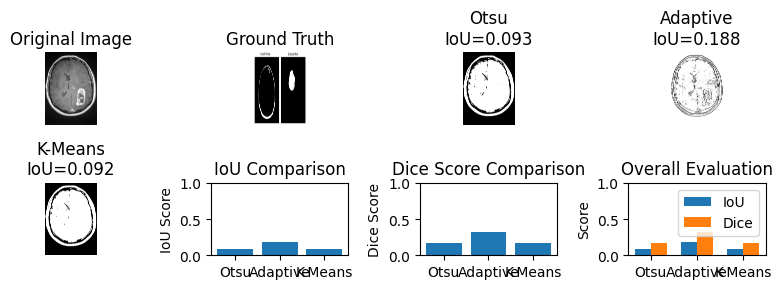

In [ ]:
# Upload original image and ground-truth mask
print("Upload ORIGINAL image:")
uploaded1 = files.upload()
image_file = next(iter(uploaded1))

print("Upload GROUND-TRUTH mask:")
uploaded2 = files.upload()
mask_file = next(iter(uploaded2))

# Read images
image = cv2.imread(image_file, cv2.IMREAD_GRAYSCALE)
ground_truth = cv2.imread(mask_file, cv2.IMREAD_GRAYSCALE)

if image is None or ground_truth is None:
    print("Error: Could not load images.")

else:

    # Resize ground truth to image size
    ground_truth = cv2.resize(
        ground_truth,
        (image.shape[1], image.shape[0])
    )

    # Convert ground truth to binary
    _, ground_truth = cv2.threshold(
        ground_truth, 127, 255,
        cv2.THRESH_BINARY
    )

    # METHOD 1: OTSU THRESHOLDING
    _, otsu = cv2.threshold(
        image,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # METHOD 2: ADAPTIVE THRESHOLDING
    adaptive = cv2.adaptiveThreshold(
        image,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        21,
        5
    )

    # METHOD 3: K-MEANS SEGMENTATION
    pixels = image.reshape((-1, 1)).astype(np.float32)

    criteria = (
        cv2.TERM_CRITERIA_EPS +
        cv2.TERM_CRITERIA_MAX_ITER,
        100,
        0.2
    )

    K = 3

    _, labels, centers = cv2.kmeans(
        pixels,
        K,
        None,
        criteria,
        10,
        cv2.KMEANS_PP_CENTERS
    )

    centers = np.uint8(centers)

    segmented = centers[labels.flatten()]
    segmented = segmented.reshape(image.shape)

    # Convert K-means result to binary
    _, kmeans_mask = cv2.threshold(
        segmented,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # IOU FUNCTION
    def calculate_iou(predicted, ground_truth):

        predicted = predicted > 0
        ground_truth = ground_truth > 0

        intersection = np.logical_and(
            predicted,
            ground_truth
        ).sum()

        union = np.logical_or(
            predicted,
            ground_truth
        ).sum()

        if union == 0:
            return 1.0

        return intersection / union

    # DICE FUNCTION
    def calculate_dice(predicted, ground_truth):

        predicted = predicted > 0
        ground_truth = ground_truth > 0

        intersection = np.logical_and(
            predicted,
            ground_truth
        ).sum()

        total = predicted.sum() + ground_truth.sum()

        if total == 0:
            return 1.0

        return (2 * intersection) / total

    # CALCULATE SCORES

    methods = {
        "Otsu": otsu,
        "Adaptive": adaptive,
        "K-Means": kmeans_mask
    }

    iou_scores = []
    dice_scores = []

    print("\nSEGMENTATION EVALUATION")
    print("-" * 45)

    for name, mask in methods.items():

        iou = calculate_iou(mask, ground_truth)
        dice = calculate_dice(mask, ground_truth)

        iou_scores.append(iou)
        dice_scores.append(dice)

        print(
            f"{name:12s} "
            f"IoU = {iou:.4f}   "
            f"Dice = {dice:.4f}"
        )

    # FIND BEST METHOD

    best_iou_index = np.argmax(iou_scores)
    best_dice_index = np.argmax(dice_scores)

    print("\nBest IoU Method:",
          list(methods.keys())[best_iou_index])

    print("Best Dice Method:",
          list(methods.keys())[best_dice_index])

    # VISUAL DASHBOARD

    plt.figure(figsize=(8, 3))

    plt.subplot(2, 4, 1)
    plt.imshow(image, cmap="gray")
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(2, 4, 2)
    plt.imshow(ground_truth, cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(2, 4, 3)
    plt.imshow(otsu, cmap="gray")
    plt.title(
        f"Otsu\nIoU={iou_scores[0]:.3f}"
    )
    plt.axis("off")

    plt.subplot(2, 4, 4)
    plt.imshow(adaptive, cmap="gray")
    plt.title(
        f"Adaptive\nIoU={iou_scores[1]:.3f}"
    )
    plt.axis("off")

    plt.subplot(2, 4, 5)
    plt.imshow(kmeans_mask, cmap="gray")
    plt.title(
        f"K-Means\nIoU={iou_scores[2]:.3f}"
    )
    plt.axis("off")

    plt.subplot(2, 4, 6)
    plt.bar(methods.keys(), iou_scores)
    plt.ylim(0, 1)
    plt.title("IoU Comparison")
    plt.ylabel("IoU Score")

    plt.subplot(2, 4, 7)
    plt.bar(methods.keys(), dice_scores)
    plt.ylim(0, 1)
    plt.title("Dice Score Comparison")
    plt.ylabel("Dice Score")

    plt.subplot(2, 4, 8)

    x = np.arange(len(methods))
    width = 0.35

    plt.bar(
        x - width/2,
        iou_scores,
        width,
        label="IoU"
    )

    plt.bar(
        x + width/2,
        dice_scores,
        width,
        label="Dice"
    )

    plt.xticks(x, methods.keys())
    plt.ylim(0, 1)
    plt.ylabel("Score")
    plt.title("Overall Evaluation")
    plt.legend()

    plt.tight_layout()
    plt.show()